# Transfer-likelihood feasibility

Real-data label audit only; no model fitting. Target: reported permanent club-to-club move within 12 months after 30 June. Unknown follow-up is never labelled zero.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / 'src').exists(): ROOT = ROOT.parent
report = json.loads((ROOT / 'reports/transfer_likelihood/label_audit.json').read_text(encoding='utf-8'))
coverage = pd.read_csv(ROOT / 'reports/transfer_likelihood/label_coverage.csv')
quality = pd.read_csv(ROOT / 'reports/transfer_likelihood/event_quality.csv')
assert coverage.cases.sum() == report['cases']
assert report['training_eligible_cases'] == 0
pd.Series(report['status_counts'], name='player_season_cases').to_frame()

mkdir -p failed for path /home/agent/.config/matplotlib: [Errno 30] Read-only file system: '/home/agent/.config/matplotlib'


Matplotlib created a temporary cache directory at /tmp/matplotlib-9kai2_1w because there was an issue with the default path (/home/agent/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Fontconfig error: No writable cache directories


,player_season_cases
no_recorded_permanent_transfer_followup_unknown,5036
reported_permanent_transfer_pending_review,1726
identity_unmapped,632


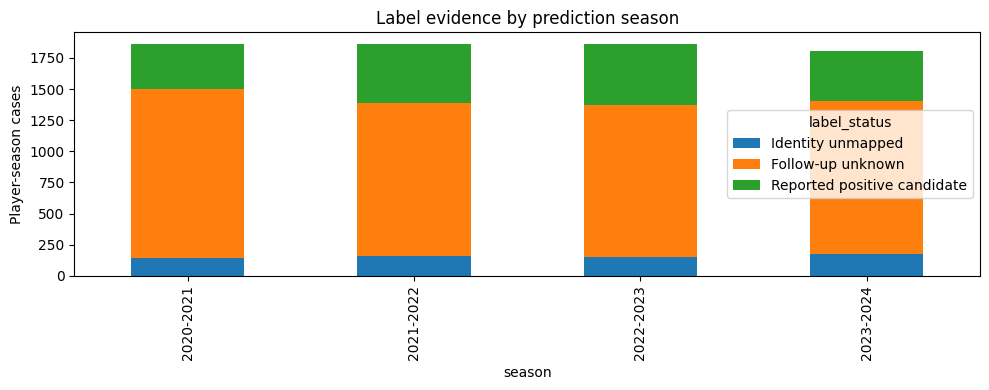

,season,league,label_status,cases
0,2020-2021,Bundesliga,identity_unmapped,21
1,2020-2021,Bundesliga,no_recorded_permanent_transfer_followup_unknown,240
2,2020-2021,Bundesliga,reported_permanent_transfer_pending_review,77
3,2020-2021,La Liga,identity_unmapped,51
4,2020-2021,La Liga,no_recorded_permanent_transfer_followup_unknown,282
5,2020-2021,La Liga,reported_permanent_transfer_pending_review,60
6,2020-2021,Ligue 1,identity_unmapped,24
7,2020-2021,Ligue 1,no_recorded_permanent_transfer_followup_unknown,267
8,2020-2021,Ligue 1,reported_permanent_transfer_pending_review,86
9,2020-2021,Premier League,identity_unmapped,17


In [2]:
labels = {'identity_unmapped':'Identity unmapped', 'no_recorded_permanent_transfer_followup_unknown':'Follow-up unknown', 'reported_permanent_transfer_pending_review':'Reported positive candidate'}
summary = coverage.pivot_table(index='season', columns='label_status', values='cases', aggfunc='sum', fill_value=0).rename(columns=labels)
summary.plot.bar(stacked=True, figsize=(10,4), ylabel='Player-season cases', title='Label evidence by prediction season')
plt.tight_layout()
plt.show()
coverage

## Interpretation

1,726 reported positive candidates, 5,036 cases with no recorded qualifying move but unknown follow-up, and 632 unmapped cases. Counts refer to player-seasons, not distinct players. There are no verified negative labels. Identity proposals and source-use restrictions remain unresolved, so no cases are training eligible. Treating unknown outcomes as zero would confound missing archive coverage with staying.

Date/season conflicts include plausible boundary assignments. They are excluded pending review, not declared invalid transfers.

In [3]:
quality.groupby(['event_kind', 'event_date_usable']).events.sum().to_frame()

events
event_kind                     event_date_usable        
draft                          False                   2
                               True                  283
loan                           False                 244
                               True                41887
loan_return                    False                 393
                               True                42933
non_club_or_unknown_transition False                 563
                               True                61071
other_or_unknown               True                   35
permanent_club_change          False                1214
                               True               217295

## Next steps

Establish permitted model use, review identities, adjudicate dates and verify follow-up. Freeze historical features; exclude future destination, fees, valuations and performance. Only then compare historical-rate, logistic regression and gradient-boosted models chronologically. Planned metrics: PR-AUC, shortlist precision/recall, Brier score, calibration and player-block uncertainty. No predictive metrics have been computed here. See docs/TRANSFER_LIKELIHOOD.md for definitions and limitations.